# Imports

In [1]:
import os
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
sns.set_theme("talk")

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, TensorBoard, EarlyStopping

from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import eli5
from eli5.sklearn import PermutationImportance
import shap


from tensorflow.keras.regularizers import l2
from tensorflow.keras.regularizers import l1
from scipy import stats

import itertools

# Preparing Data

In [2]:
progs = pd.read_csv('results_s18.csv')
progs.head()

,zams,xi_1.5,xi_1.75,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe,exploded,max_antesonic,central_entropy,central_ye,central_density
0,12.00,0.706436,0.301518,0.129584,0.044313,0.025005,0.015826,0.009215,1.593086,2.956980e+08,1.396419,1.483308e+08,False,0.130846,0.613764,0.434087,9.871059e+09
1,12.01,0.666355,0.287077,0.133169,0.046851,0.026113,0.016529,0.009806,1.606168,3.364827e+08,1.375800,1.399285e+08,False,0.127588,0.605900,0.433246,1.078320e+10
2,12.02,0.735530,0.321768,0.138306,0.046452,0.025535,0.015812,0.008812,1.560773,2.491711e+08,1.407802,1.529686e+08,False,0.129664,0.618427,0.433623,9.509927e+09
3,12.03,0.869549,0.393744,0.144617,0.030037,0.016538,0.011069,0.007128,1.565078,2.100526e+08,1.394626,1.331820e+08,False,0.171213,0.693837,0.439184,6.368385e+09
4,12.04,0.868106,0.360651,0.140825,0.035509,0.019835,0.013299,0.008484,1.550249,2.007662e+08,1.397803,1.335820e+08,True,0.439453,0.694285,0.438678,6.485156e+09


In [3]:
progs = progs.drop(columns=['xi_1.5','xi_1.75','xi_2.0','xi_2.25','xi_2.5','xi_2.75', 'central_ye', 'central_density'])
progs.head()

,zams,xi_3.0,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe,exploded,max_antesonic,central_entropy
0,12.00,0.009215,1.593086,2.956980e+08,1.396419,1.483308e+08,False,0.130846,0.613764
1,12.01,0.009806,1.606168,3.364827e+08,1.375800,1.399285e+08,False,0.127588,0.605900
2,12.02,0.008812,1.560773,2.491711e+08,1.407802,1.529686e+08,False,0.129664,0.618427
3,12.03,0.007128,1.565078,2.100526e+08,1.394626,1.331820e+08,False,0.171213,0.693837
4,12.04,0.008484,1.550249,2.007662e+08,1.397803,1.335820e+08,True,0.439453,0.694285


In [4]:
progs['xi_Si'] = progs['coremass_Si']/(progs['corerad_Si']/1e8)
progs['xi_Fe'] = progs['coremass_Fe']/(progs['corerad_Fe']/1e8)
progs.head()

,zams,xi_3.0,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe,exploded,max_antesonic,central_entropy,xi_Si,xi_Fe
0,12.00,0.009215,1.593086,2.956980e+08,1.396419,1.483308e+08,False,0.130846,0.613764,0.538754,0.941423
1,12.01,0.009806,1.606168,3.364827e+08,1.375800,1.399285e+08,False,0.127588,0.605900,0.477341,0.983216
2,12.02,0.008812,1.560773,2.491711e+08,1.407802,1.529686e+08,False,0.129664,0.618427,0.626386,0.920321
3,12.03,0.007128,1.565078,2.100526e+08,1.394626,1.331820e+08,False,0.171213,0.693837,0.745089,1.047158
4,12.04,0.008484,1.550249,2.007662e+08,1.397803,1.335820e+08,True,0.439453,0.694285,0.772166,1.046400


In [5]:
progs = progs.drop(columns=['coremass_Si','corerad_Si','coremass_Fe','corerad_Fe'])
progs.head()

,zams,xi_3.0,exploded,max_antesonic,central_entropy,xi_Si,xi_Fe
0,12.00,0.009215,False,0.130846,0.613764,0.538754,0.941423
1,12.01,0.009806,False,0.127588,0.605900,0.477341,0.983216
2,12.02,0.008812,False,0.129664,0.618427,0.626386,0.920321
3,12.03,0.007128,False,0.171213,0.693837,0.745089,1.047158
4,12.04,0.008484,True,0.439453,0.694285,0.772166,1.046400


In [6]:
exploded = progs['exploded']
progs = progs.drop(columns=['exploded'])
progs['exploded'] = exploded
progs.head()

,zams,xi_3.0,max_antesonic,central_entropy,xi_Si,xi_Fe,exploded
0,12.00,0.009215,0.130846,0.613764,0.538754,0.941423,False
1,12.01,0.009806,0.127588,0.605900,0.477341,0.983216,False
2,12.02,0.008812,0.129664,0.618427,0.626386,0.920321,False
3,12.03,0.007128,0.171213,0.693837,0.745089,1.047158,False
4,12.04,0.008484,0.439453,0.694285,0.772166,1.046400,True


In [7]:
max_antesonic = progs['max_antesonic']
progs = progs.drop(columns=['max_antesonic'])
progs['max_antesonic'] = max_antesonic
progs.head()

,zams,xi_3.0,central_entropy,xi_Si,xi_Fe,exploded,max_antesonic
0,12.00,0.009215,0.613764,0.538754,0.941423,False,0.130846
1,12.01,0.009806,0.605900,0.477341,0.983216,False,0.127588
2,12.02,0.008812,0.618427,0.626386,0.920321,False,0.129664
3,12.03,0.007128,0.693837,0.745089,1.047158,False,0.171213
4,12.04,0.008484,0.694285,0.772166,1.046400,True,0.439453


In [133]:
progs = progs.drop(columns=['max_antesonic'])
progs.head()

,zams,xi_3.0,central_entropy,xi_Si,xi_Fe
0,12.00,0.009215,0.613764,0.538754,0.941423
1,12.01,0.009806,0.605900,0.477341,0.983216
2,12.02,0.008812,0.618427,0.626386,0.920321
3,12.03,0.007128,0.693837,0.745089,1.047158
4,12.04,0.008484,0.694285,0.772166,1.046400


# Predicting Exploded

In [8]:
progs['exploded'] = progs['exploded'].astype(int)

In [9]:
Y = np.asarray(progs['exploded'])

In [10]:
progs = progs.drop(columns=['exploded'])

In [147]:
X = np.asarray(progs) #needs to be an array for tensorflow later on

In [148]:
# Preprocess the data (normalize)
X_nn = X.copy()
# X_nn[:,0] = np.log(X_nn[:,0])
# X_nn[:,4] = np.exp(X_nn[:,4])

# Perform the Box-Cox transformation to normalize
transformed_column3, lambda_value3 = stats.boxcox(X_nn[:,0])
transformed_columnms, lambda_valuems = stats.boxcox(X_nn[:,1])
transformed_columnmf, lambda_valuemf = stats.boxcox(X_nn[:,2])
transformed_columnrs, lambda_valuers = stats.boxcox(X_nn[:,3])
transformed_columnrf, lambda_valuerf = stats.boxcox(X_nn[:,4])


# Update the transformed column in X_nn
X_nn[:,0] = transformed_column3
X_nn[:,1] = transformed_columnms
X_nn[:,2] = transformed_columnmf
X_nn[:,3] = transformed_columnrs
X_nn[:,4] = transformed_columnrf

X_mean = X_nn.mean(axis=0)
X_std = X_nn.std(axis=0)

X_nn = (X_nn - X_mean) / (X_std)

Y_nn = Y.copy()
Y_mean = Y_nn.mean(axis=0)
Y_std = Y_nn.std(axis=0)

Y_nn = (Y_nn - Y_mean) / (Y_std)

In [149]:
(X_train, 
 X_val,
 Y_train,
 Y_val) = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

In [150]:
print(X_train.shape)
print(Y_train.shape)
print(X_val.shape)
print(Y_val.shape)

(1050, 5)
(1050,)
(450, 5)
(450,)


# Building the model.

In [151]:
# Build the model
beta = 0
model = Sequential()
model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))

model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

model.compile(loss='mean_squared_error', optimizer='adam')
print(model.summary())

Model: "sequential_10"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_70 (Dense)             (None, 64)                384       
_________________________________________________________________
dropout_60 (Dropout)         (None, 64)                0         
_________________________________________________________________
dense_71 (Dense)             (None, 64)                4160      
_________________________________________________________________
dropout_61 (Dropout)         (None, 64)                0         
_________________________________________________________________
dense_72 (Dense)             (None, 64)                4160      
_________________________________________________________________
dropout_62 (Dropout)         (None, 64)                0         
_________________________________________________________________
dense_73 (Dense)             (None, 64)              

In [152]:
def train(model, X_train, Y_train, X_val, Y_val, **kwargs):
    
    X_train = tf.convert_to_tensor(X_train)
    Y_train = tf.convert_to_tensor(Y_train)
    Train = (X_train, Y_train)

    X_val = tf.convert_to_tensor(X_val)
    Y_val = tf.convert_to_tensor(Y_val)
    Val = (X_val, Y_val)
    
    cur_date_str = datetime.now().strftime("%Y-%m-%dT%H-%M-%S")
    logdir="logs/scalars/" + cur_date_str
    tensorboard_callback = TensorBoard(log_dir=logdir)
    checkpoints_dir = os.path.join('checkpoints', cur_date_str)
    os.makedirs(checkpoints_dir, exist_ok=True)
    checkpointer_best = ModelCheckpoint(monitor='val_loss', 
                                        filepath=os.path.join(checkpoints_dir, 'grid_weights_best.h5'), 
                                        save_best_only=True, save_weights_only=True)
    early_stopping = EarlyStopping(monitor='val_loss', 
                                   min_delta=0, patience=500, 
                                   verbose=0, mode='auto', baseline=None, 
                                   restore_best_weights=True)
    fit_kwargs = dict(validation_data=Val, 
                  epochs=400000, batch_size=8,
                  callbacks=[checkpointer_best, tensorboard_callback, early_stopping], 
                  verbose=0)
    fit_kwargs.update(kwargs)

    model.fit(*Train, **fit_kwargs)

# Train and Test

In [153]:
%%time
train(model, X_train, Y_train, X_val, Y_val, verbose = 1)

Epoch 1/400000
132/132 [==============================] - 1s 4ms/step - loss: 1.4984 - val_loss: 0.4396
Epoch 2/400000
132/132 [==============================] - 0s 2ms/step - loss: 0.9554 - val_loss: 0.5026
Epoch 3/400000
132/132 [==============================] - 0s 2ms/step - loss: 0.8244 - val_loss: 0.3381
Epoch 4/400000
132/132 [==============================] - 0s 2ms/step - loss: 0.7751 - val_loss: 0.3237
Epoch 5/400000
132/132 [==============================] - 0s 2ms/step - loss: 0.7043 - val_loss: 0.3104
Epoch 6/400000
132/132 [==============================] - 0s 2ms/step - loss: 0.5806 - val_loss: 0.3159
Epoch 7/400000
132/132 [==============================] - 0s 2ms/step - loss: 0.5010 - val_loss: 0.3027
Epoch 8/400000
132/132 [==============================] - 0s 2ms/step - loss: 0.4800 - val_loss: 0.2539
Epoch 9/400000
132/132 [==============================] - 0s 2ms/step - loss: 0.4238 - val_loss: 0.2566
Epoch 10/400000
132/132 [==============================] - 0s 2m

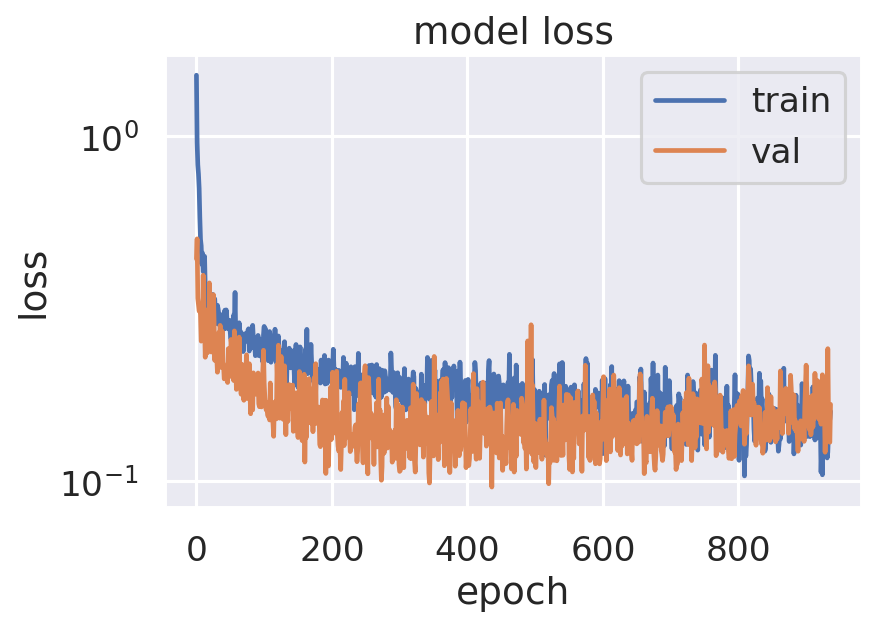

In [154]:
# #https://machinelearningmastery.com/display-deep-learning-model-training-history-in-keras/
plt.figure(dpi=150)
plt.plot(model.history.history['loss'])
plt.plot(model.history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'])
plt.yscale("log")
plt.show()

In [155]:
# # get the neural networks prediction (with validation dataset)
Y_nn_test = model(X_val, training = False)
Y_emu_test = np.exp(Y_std * Y_nn_test + Y_mean) - 1e-5

In [156]:
Y_emu_test = (Y_emu_test-np.min(Y_emu_test))/(np.max(Y_emu_test)-np.min(Y_emu_test))
Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))

In [157]:
for i, man in enumerate(Y_emu_test):
    if man >=0.5:
        Y_emu_test[i]=1
    else:
        Y_emu_test[i]=0

# Results

In [158]:
accuracy_score(Y_val, Y_emu_test)

0.98

In [161]:
# accuracy = [0.9977777777777778,
#             1,
#             1,
#             1,
#             1,
#             1.0,
#             1.0,
#             1,
#             1,
#             1
#            ]
# print('Average Accuracy->')
# print(np.average(accuracy))


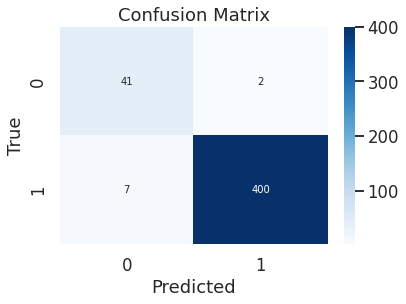

In [160]:
cm = confusion_matrix(Y_val,Y_emu_test)
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')

plt.show()
